# COATI: train a vector field and visualize UMAP velocity

Synthetic data only. Choose `multimodal` and `balanced`, train the vector field,
then inspect velocities and trajectories separately. Install `.[visualization,notebooks]`.
The existing training engine is used unchanged.

In [1]:
from pathlib import Path
import uuid
import numpy as np
import pandas as pd
import anndata as ad
from umap import UMAP
import matplotlib.pyplot as plt
import coati as ct
%matplotlib inline

/Users/jingfeng/local/project/COATI/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
multimodal = False
balanced = True
config = ct.Config(multimodal=multimodal, balanced=balanced,
                   iterations=100, batch_size=64, learning_rate=1e-3,
                   seed=7, map_type="kernel")
config.to_dict()

{'time_plot': False,
 'reverseMatching': False,
 'accumulate_training': True,
 'MixSampling': False,
 'seed': 7,
 'gpu': 0,
 'unbalancedModel': False,
 'alpha_growth': 0.0,
 'mass_loss': False,
 'mass_coefficient': 0.0,
 'global_mass': False,
 'hidden_dim': 64,
 'n_layers': 2,
 'activation': 'leaky_relu',
 'niters': 100,
 'lr': 0.001,
 'num_samples': 64,
 'median_n_sample': 128,
 'floor_n_sample': 64,
 'support_points': False,
 'dt': 0.1,
 'density_coefficient': 0.0,
 'pdf_lossMSE': False,
 'pdf_coefficient': 50.0,
 'sinkhorn_pdf': True,
 'energy_coefficient': 1.0,
 'density_topk': 25,
 'density_hinge': 0.01,
 'terminal_density_weight': 1.0,
 'sync_loss': False,
 'sync_weight': 0.0,
 'sync_density_loss': False,
 'sync_pdf_loss': True,
 'map_type': 'kernel',
 'kernel_sigma': 0.01,
 'adaptive_lambda': False,
 'blur_coeff': 0.05,
 'floor_buffer_std': 0.0,
 'lambda_max_pri': 100.0,
 'lambda_max_sec': 100.0,
 'lambda_min_pri': 5.0,
 'lambda_min_sec': 5.0,
 'eta_lambda_pri': 10.0,
 'eta_lamb

In [3]:
data = ct.datasets.paired(n=128, seed=7) if multimodal else ct.datasets.split(n=128, seed=7)
x = np.concatenate(data.primary)
cell_times = np.repeat(data.times, [len(part) for part in data.primary])
adata = ad.AnnData(x, obs=pd.DataFrame({"time": cell_times,
                    "stage": [f"t={t:g}" for t in cell_times]},
                    index=[f"toy-{i}" for i in range(len(x))]))
adata.obsm["X_pca"] = x.copy()  # prepared coordinates used in model training
adata

AnnData object with n_obs × n_vars = 384 × 2
    obs: 'time', 'stage'
    obsm: 'X_pca'

In [4]:
output_dir = Path("outputs") / ("velocity-" + uuid.uuid4().hex[:8])
result = ct.train_vector_field(data, config, output_dir=output_dir)
result.evaluate()

{'endpoint_sinkhorn_before': 0.15261565148830414,
 'endpoint_sinkhorn_after': 0.01641431637108326,
 'kinetic_energy_mean': 0.13641740381717682,
 'endpoint_sampling_floor': 0.0014929494354873896}

Velocity: (384, 2) Trajectory: (41, 128, 2)


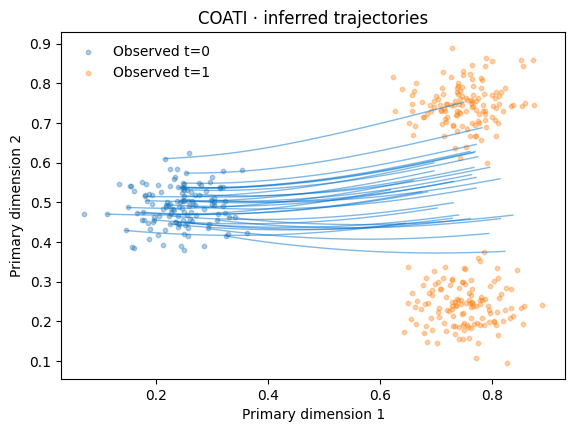

In [5]:
velocity = result.compute_velocity()
trajectory = result.predict_trajectory()
print("Velocity:", velocity.shape, "Trajectory:", trajectory["primary"].shape)
result.plot_trajectory()
plt.show()

In [6]:
reducer = UMAP(n_neighbors=30, min_dist=.35, random_state=7, n_jobs=1)
adata.obsm["X_umap"] = reducer.fit_transform(adata.obsm["X_pca"])

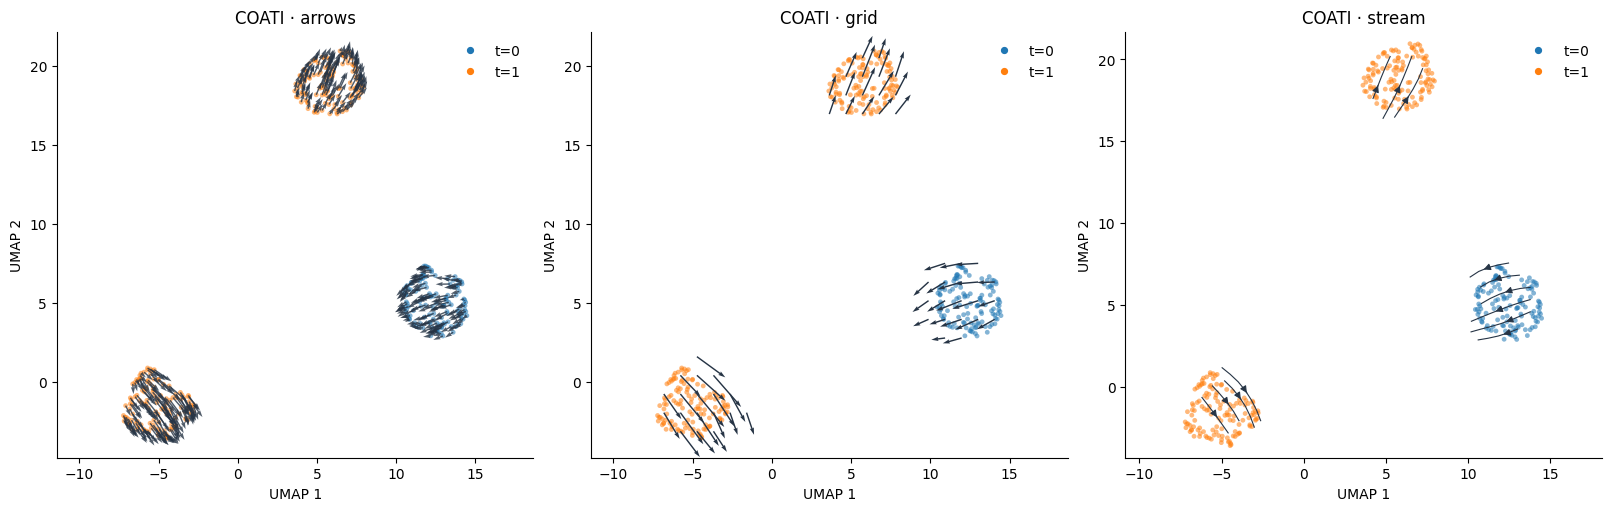

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
for ax, style in zip(axes, ["arrows", "grid", "stream"]):
    result.plot_velocity(adata, use_rep="X_pca", time_key="time", color="stage",
                         style=style, ax=ax, title=f"COATI · {style}")
fig.savefig(result.output_dir / "velocity_umap.png", dpi=180)
fig.savefig(result.output_dir / "velocity_umap.pdf")
plt.show()

## Store and reload

Plotting is read-only. `write_velocity` explicitly stores numeric vectors in AnnData.
These are learned COATI velocities projected by a local linear approximation, not
splicing-based RNA velocity or an analytic UMAP Jacobian. With all stages shown,
cells are evaluated at their own observation times.

In [8]:
result.write_velocity(adata, use_rep="X_pca", time_key="time")
adata.write_h5ad(result.output_dir / "velocity.h5ad")
restored = ct.load_result(result.output_dir)
np.testing.assert_array_equal(result.compute_velocity(), restored.compute_velocity())
print(result.output_dir)

/Users/jingfeng/local/project/COATI/outputs/velocity-62fc5e19
